In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn

In [2]:
from sklearn.datasets import fetch_california_housing

In [3]:
housing = fetch_california_housing()

In [4]:
df = pd.DataFrame(housing.data, columns=housing.feature_names)

In [5]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [6]:
df['MedHouseVal']=housing.target

In [58]:
df.shape

(20640, 9)

In [59]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [60]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


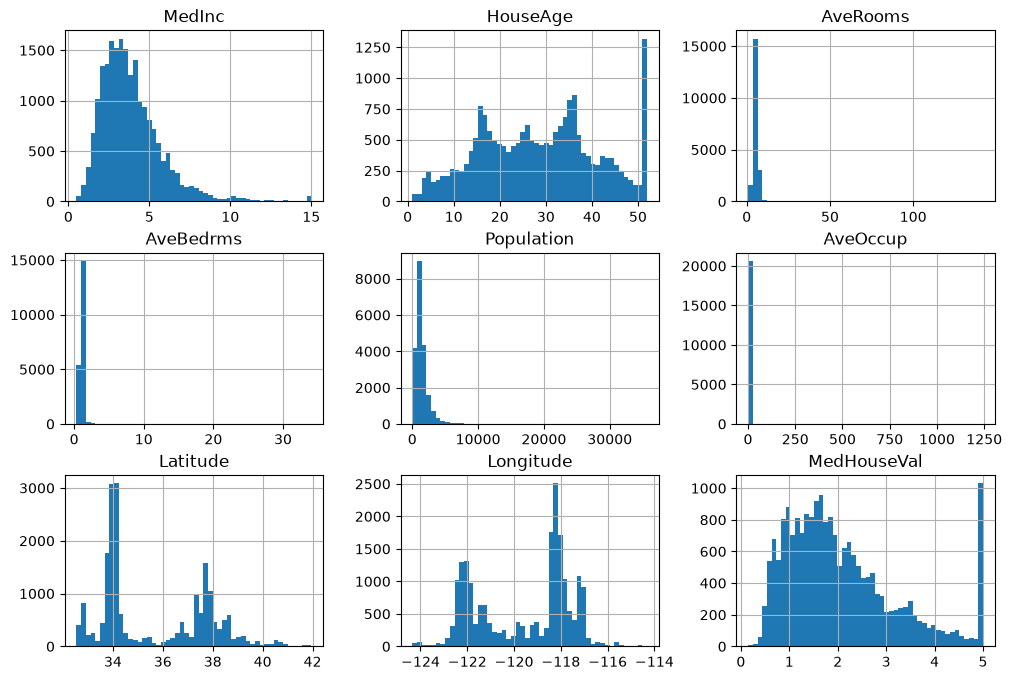

In [61]:
df.hist(bins=50, figsize=(12,8))
plt.show()

In [62]:
columns = df.select_dtypes(include=['float']).columns

In [63]:
columns

Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'MedHouseVal'],
      dtype='str')

In [64]:
df.isnull().sum().sum()

np.int64(0)

In [65]:
df.isna().sum().sum()

np.int64(0)

In [66]:
print(df['MedHouseVal'].min())
print(df['MedHouseVal'].max())


0.14999
5.00001


In [7]:
df['income_cat'] = pd.cut(df['MedInc'],
                      bins=[0., 1.5, 3.0, 4.5, 6., np.inf],
                      labels=[1,2,3,4,5]
)

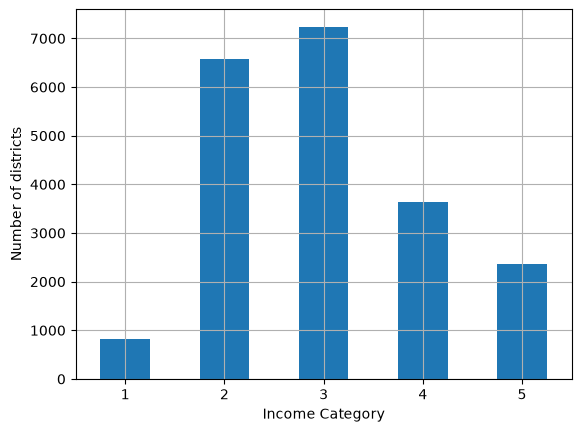

In [7]:
df['income_cat'].value_counts().sort_index().plot.bar(rot=0, grid=True)
plt.xlabel('Income Category')
plt.ylabel('Number of districts')
plt.show()

In [69]:
df['income_cat'].value_counts()/len(df)

income_cat
3    0.350581
2    0.318847
4    0.176308
5    0.114438
1    0.039826
Name: count, dtype: float64

In [8]:
from sklearn.model_selection import train_test_split

In [9]:
strat_train_set, strat_test_set = train_test_split(
    df, test_size=0.2, stratify=df['income_cat'], random_state=42
)

In [72]:
print(len(strat_train_set))
print(len(strat_test_set))

16512
4128


In [73]:
strat_test_set['income_cat'].value_counts()/len(strat_test_set)

income_cat
3    0.350533
2    0.318798
4    0.176357
5    0.114341
1    0.039971
Name: count, dtype: float64

In [74]:
strat_train_set['income_cat'].value_counts()/len(strat_train_set)

income_cat
3    0.350594
2    0.318859
4    0.176296
5    0.114462
1    0.039789
Name: count, dtype: float64

In [10]:
for set_ in (strat_train_set, strat_test_set):
    set_.drop("income_cat", axis=1, inplace=True)

### Exploratory Data Analysis (EDA)

1. **Feature Distributions:** Histograms revealed right-skewed distributions in `MedInc`, `AveRooms`, `AveBedrms`, `Population`, and `AveOccup`. `HouseAge` showed a concentration near its upper limit, while `MedHouseVal` exhibited a cap near $500,000.

2. **Geographical Visualization:** The latitude–longitude scatter plot visualizes California districts, with point sizes representing population and colors representing median house values. It helps identify geographic patterns in housing prices and population density.

3. **Feature Relationships:** Correlation analysis and scatter matrices revealed a relatively strong positive linear relationship between `MedInc` and `MedHouseVal`. Other features showed weaker individual linear relationships, while extreme values and the target's upper cap highlighted potential challenges for prediction.

In [11]:
housing = strat_train_set.copy()

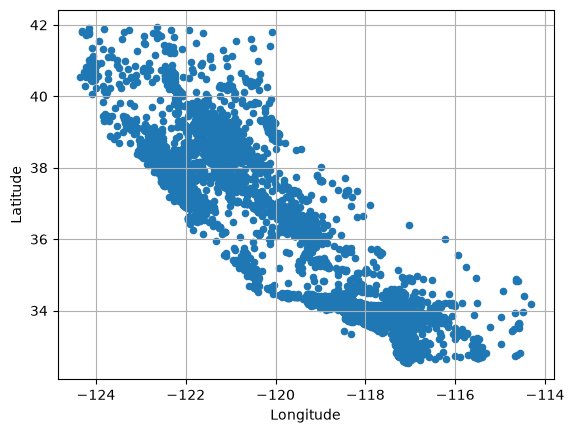

In [138]:
housing.plot(kind='scatter', x='Longitude', y='Latitude', grid=True)
plt.show()

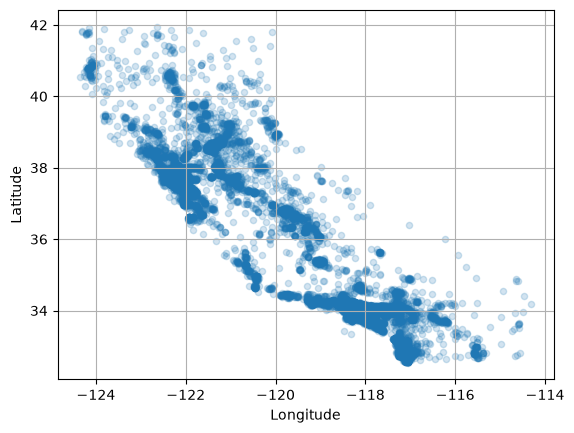

In [78]:
housing.plot(kind='scatter', x='Longitude', y='Latitude', grid=True, alpha=0.2)
plt.show()

In [79]:
df.columns

Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'MedHouseVal', 'income_cat'],
      dtype='str')

In [80]:
housing.columns

Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'MedHouseVal'],
      dtype='str')

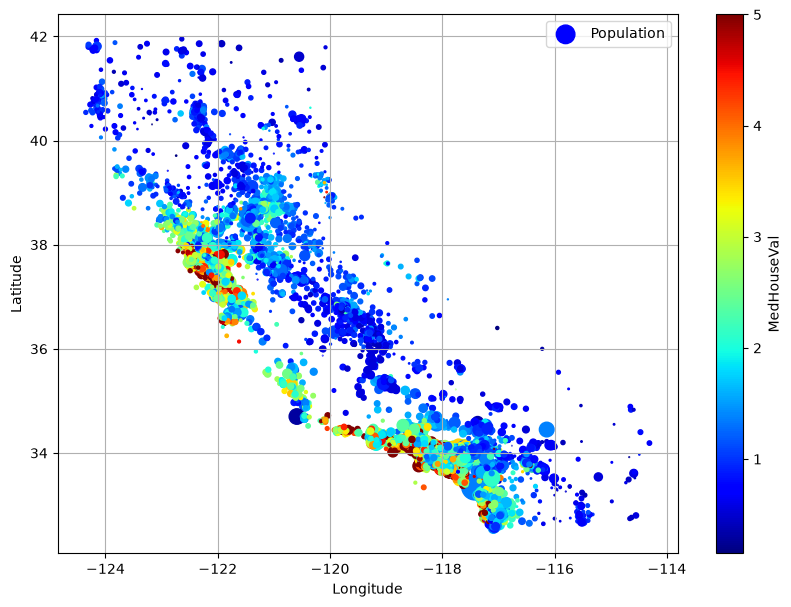

In [81]:
housing.plot(kind='scatter', x='Longitude', y='Latitude', grid=True,
             s=housing['Population']/100, label='Population',
             c='MedHouseVal', cmap='jet', colorbar=True,
             legend=True, sharex=False, figsize=(10,7))
plt.show()

In [82]:
corr_matrix = housing.corr()

In [83]:
corr_matrix['MedHouseVal'].sort_values(ascending=False)

MedHouseVal    1.000000
MedInc         0.687151
AveRooms       0.146255
HouseAge       0.114146
AveOccup      -0.021991
Population    -0.026882
AveBedrms     -0.043294
Longitude     -0.047466
Latitude      -0.142673
Name: MedHouseVal, dtype: float64

In [84]:
from pandas.plotting import scatter_matrix

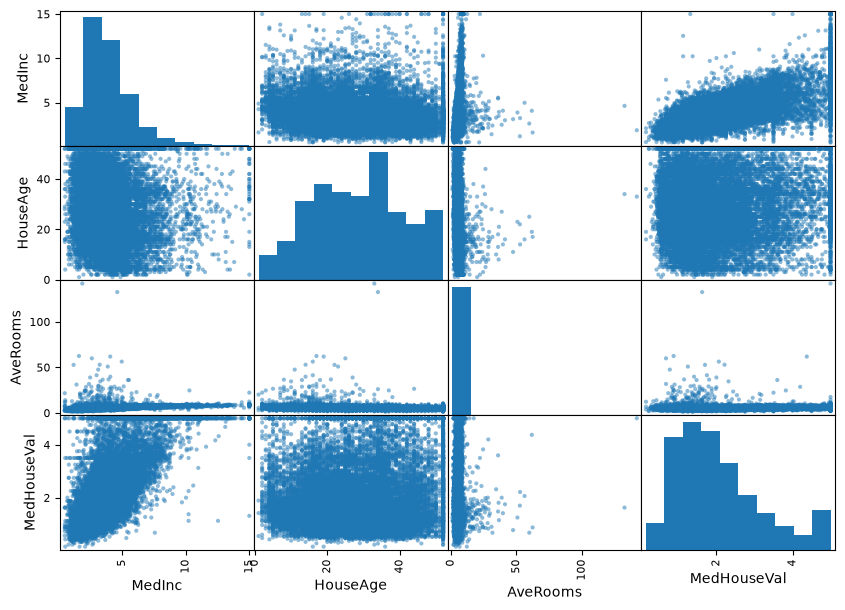

In [85]:
attributes = ['MedInc', 'HouseAge', 'AveRooms', 'MedHouseVal']
scatter_matrix(housing[attributes], figsize=(10,7))
plt.show()

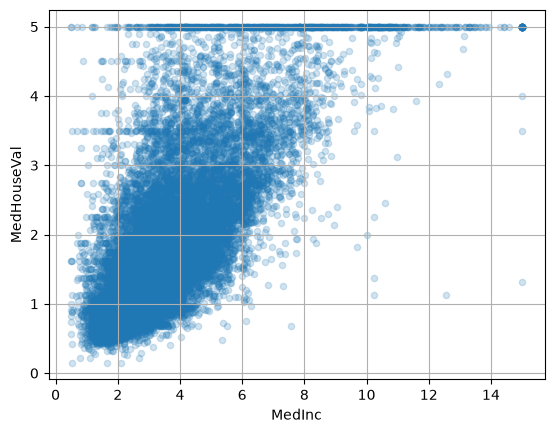

In [86]:
housing.plot(kind='scatter', y='MedHouseVal', x='MedInc', alpha=0.2, grid=True)
plt.show()

In [87]:
# housing['latlong_ratio'] = housing['Latitude']/housing['Longitude']
housing['incpop_ratio'] = housing['MedInc']/housing['Population']
# housing['bed_room'] = housing['AveBedrms'] / housing['AveRooms']
# housing['lat_long'] = housing['Latitude']+housing['Longitude']

In [88]:
corr_matrix = housing.corr()

corr_matrix['MedHouseVal'].sort_values(ascending=False)

MedHouseVal     1.000000
MedInc          0.687151
AveRooms        0.146255
incpop_ratio    0.115975
HouseAge        0.114146
AveOccup       -0.021991
Population     -0.026882
AveBedrms      -0.043294
Longitude      -0.047466
Latitude       -0.142673
Name: MedHouseVal, dtype: float64

In [12]:
housing = strat_train_set.drop('MedHouseVal', axis=1)
housing_labels = strat_train_set['MedHouseVal'].copy()

In [13]:
from sklearn.impute import SimpleImputer

In [91]:
imputer = SimpleImputer(strategy='median')

In [92]:
housing_num = housing.select_dtypes(include=[np.number])

In [35]:
imputer.fit(housing_num)

NameError: name 'imputer' is not defined

In [94]:
X = imputer.transform(housing_num)

In [95]:
housing_tr = pd.DataFrame(X, columns=housing_num.columns,
                          index=housing_num.index)

In [96]:
housing_tr.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
12655,2.1736,29.0,5.485836,1.128895,2237.0,3.168555,38.52,-121.46
15502,6.3373,7.0,6.927083,1.113281,2015.0,2.623698,33.09,-117.23
2908,2.8750,44.0,5.393333,1.033333,667.0,2.223333,35.37,-119.04
14053,2.2264,24.0,3.886128,1.074534,898.0,1.859213,32.75,-117.13
20496,4.4964,27.0,6.096552,1.113793,1837.0,3.167241,34.28,-118.70


In [97]:
housing_tr.isnull().sum()

MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
dtype: int64

In [98]:
housing_tr.shape

(16512, 8)

In [14]:
from sklearn.preprocessing import StandardScaler

In [100]:
std_scaler = StandardScaler()
housing_num_std_scaled = std_scaler.fit_transform(housing_num)


In [101]:
X = std_scaler.transform(housing_num)


In [102]:
housing_st = pd.DataFrame(X,columns=housing_num.columns,
                          index=housing_num.index)
housing_st.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
12655,-0.893647,0.027564,0.017395,0.060107,0.732602,0.006223,1.347438,-0.941350
15502,1.292168,-1.722018,0.569256,0.029314,0.533612,-0.040811,-1.192440,1.171782
2908,-0.525434,1.220460,-0.018024,-0.128357,-0.674675,-0.075371,-0.125972,0.267581
14053,-0.865929,-0.370069,-0.595140,-0.047102,-0.467617,-0.106803,-1.351474,1.221738
20496,0.325752,-0.131489,0.251241,0.030323,0.374060,0.006109,-0.635818,0.437431


In [103]:
housing_st.shape

(16512, 8)

In [15]:
from sklearn.pipeline import Pipeline

In [16]:
preprocessing = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('standardize', StandardScaler()),
])

In [106]:
from sklearn.linear_model import LinearRegression

In [107]:
lin_reg = Pipeline([
    ('preprocessing', preprocessing),
    ('regression', LinearRegression())
])

In [108]:
lin_reg.fit(housing, housing_labels)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['MedInc','HouseAge','AveRooms',...,'AveOccup','Latitude','Longitude']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('impute', ...), ('standardize', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is t

In [109]:
lin_pred = lin_reg.predict(housing)


In [110]:
print(lin_pred[:5])
print(housing_labels.iloc[:5].values)

[0.95124793 2.84148809 1.63345708 1.61512576 2.4572297 ]
[0.721 2.796 0.827 1.125 2.383]


In [16]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, mean_squared_error

In [112]:
print("Mean Absolute Error:" ,mean_absolute_error(housing_labels,lin_pred))
print("Mean Squared Error:" ,mean_squared_error(housing_labels,lin_pred))
print("Root Mean Squared Error:" ,root_mean_squared_error(housing_labels,lin_pred))

Mean Absolute Error: 0.5330319478243065
Mean Squared Error: 0.5287374080178308
Root Mean Squared Error: 0.7271433201356049


In [113]:
from sklearn.tree import DecisionTreeRegressor

In [114]:
tree_reg =  Pipeline([
    ('preprocessing', preprocessing),
    ('regression', DecisionTreeRegressor())
])

In [115]:
tree_reg.fit(housing, housing_labels)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['MedInc','HouseAge','AveRooms',...,'AveOccup','Latitude','Longitude']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('impute', ...), ('standardize', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is t

In [116]:
tree_pred = tree_reg.predict(housing)

In [117]:
print(tree_pred[:5])
print(housing_labels.iloc[:5].values)

[0.721 2.796 0.827 1.125 2.383]
[0.721 2.796 0.827 1.125 2.383]


In [118]:
print("Mean Absolute Error:" ,mean_absolute_error(housing_labels,tree_pred))
print("Mean Squared Error:" ,mean_squared_error(housing_labels,tree_pred))
print("Root Mean Squared Error:" ,root_mean_squared_error(housing_labels,tree_pred))

Mean Absolute Error: 3.6361955651482843e-17
Mean Squared Error: 7.835101045073034e-32
Root Mean Squared Error: 2.7991250499170334e-16


In [17]:
from sklearn.model_selection import cross_val_score

In [120]:
lin_rmses = -cross_val_score(lin_reg, housing, housing_labels,
                             scoring='neg_root_mean_squared_error', cv=10)

In [121]:
tree_rmses = -cross_val_score(tree_reg, housing, housing_labels,
                             scoring='neg_root_mean_squared_error', cv=10)

In [122]:
print("List of Linear Model rmses on cross-validation:",lin_rmses)
print("List of Decision Tree  rmses on cross-validation:",tree_rmses)

List of Linear Model rmses on cross-validation: [0.74571946 0.69960318 0.7186325  0.74445404 0.70953926 0.76172221
 0.74576182 0.72513212 0.70844341 0.74241372]
List of Decision Tree  rmses on cross-validation: [0.77372532 0.72180701 0.70330317 0.71961328 0.72683368 0.76005944
 0.73848695 0.75703446 0.67578043 0.72801624]


In [123]:
pd.Series(lin_rmses).describe()

count    10.000000
mean      0.730142
std       0.020615
min       0.699603
25%       0.711813
50%       0.733773
75%       0.745403
max       0.761722
dtype: float64

In [124]:
pd.Series(tree_rmses).describe()

count    10.000000
mean      0.730466
std       0.028786
min       0.675780
25%       0.720162
50%       0.727425
75%       0.752398
max       0.773725
dtype: float64

In [35]:
from sklearn.ensemble import RandomForestRegressor

In [126]:
forest_reg = Pipeline([
    ('preprocessing', preprocessing),
    ('regression', RandomForestRegressor())
])

In [127]:
forest_reg.fit(housing,housing_labels)

KeyboardInterrupt: 

In [ ]:
baseline_rmses = evaluate_model(
    forest_reg,
    housing,
    housing_labels
)

List of RMSEs: [0.51602812 0.50350593 0.5026276  0.5302371  0.51522274]

RMSE summary
count    5.000000
mean     0.513524
std      0.011265
min      0.502628
25%      0.503506
50%      0.515223
75%      0.516028
max      0.530237
dtype: float64
Training error of model: [0.75282   2.90067   0.91982   ... 1.6952401 2.48592   0.75465  ]


In [ ]:
print("RMSE on training data:",root_mean_squared_error(housing_labels, (forest_reg.predict(housing))))

RMSE on training data: 0.19001040443799067


In [15]:
housing_clean  = housing.copy()

In [22]:
print(housing_clean.shape)
print(housing_clean.columns)
print(housing_labels.shape)

(16512, 8)
Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude'],
      dtype='str')
(16512,)


# CombinedAttributesAdder — Custom Feature Engineering Transformer

## 1. Purpose

`CombinedAttributesAdder` is a custom scikit-learn transformer that creates new features from existing numerical features. These additional features may help a machine learning model discover useful relationships in the data.

## 2. Features

| Feature | Formula | Description |
|---|---|---|
| `bed_room` | `AveBedrms / AveRooms` | Ratio of bedrooms to total rooms |
| `room_per_person` | `AveRooms / AveOccup` | Average rooms per occupant |
| `incpop_ratio` | `MedInc / Population` | Ratio of median income to population |
| `lat_long` | `Latitude + Longitude` | Sum of latitude and longitude |
| `latlong_ratio` | `Latitude / Longitude` | Ratio of latitude to longitude |

*The transformer generates only the features specified in `features_to_add`. The table lists the features discussed during development; keep it consistent with the features implemented in your current class.*

## 3. How It Works

### `__init__()`
Accepts `features_to_add`, which specifies which engineered features to create.

### `fit(X, y=None)`
Returns the transformer itself. No parameters need to be learned from the input data.

### `transform(X)`
Copies the input DataFrame, creates the selected features, and returns the modified DataFrame.

### `fit_transform(X, y=None)`
Inherited from `TransformerMixin`. It calls `fit()` followed by `transform()`.

## 4. Why Inherit from Scikit-learn Classes?

The class inherits from:

- `BaseEstimator` — provides standard estimator functionality, including parameter handling.
- `TransformerMixin` — provides the `fit_transform()` method.

This makes the custom transformer compatible with scikit-learn's `Pipeline` and cross-validation workflows.

## 5. Advantages

- Automates feature engineering.
- Keeps feature creation reusable and organized.
- Allows experiments with different feature combinations.
- Integrates with cross-validation when used inside a complete pipeline.

## 6. Important Considerations

- Division by zero can create infinite or missing values; handle zero denominators carefully.
- Feature usefulness should be evaluated with cross-validation.
- A mathematically possible feature is not necessarily a meaningful or useful predictor.

## 7. Role in the California Housing Project

We use this transformer to experiment with features such as `room_per_person` and `latlong_ratio`, then compare their predictive performance using cross-validation RMSE.


In [19]:
from sklearn.base import BaseEstimator, TransformerMixin

In [20]:
class CombinedAttributesAdder(BaseEstimator, TransformerMixin):

    def __init__(self, features_to_add=None):
        self.features_to_add = features_to_add

    def fit(self, X, y=None):
        return self


    def transform(self, X):
        # Work on a copy so the original datFrame stays unchanged
        X = X.copy()

        # Use an empty list if no features were selected
        features = self.features_to_add or []

        #Feature 1: bedroom-to-room ratio
        if "bed_room" in features:
            X['bed_room']  = (
                X['AveBedrms'] / X['AveRooms'].replace(0, np.nan)
            )

        #Feature 3: income-to-population ratio
        if "incpop_ratio" in features:
            X['incpop_ratio'] = (
                X['MedInc'] / X['Population'].replace(0, np.nan)
            )

        #Feature 4: 
        if "latlong_ratio" in features:
            X['latlong_ratio'] = X['Latitude'] / X['Longitude'].replace(0, np.nan)


        #Feature 5:
        if "room_per_person" in features:
            X["room_per_person"] = (
                X["AveRooms"] / X["AveOccup"].replace(0, np.nan)
            )

        return X




    

In [21]:
def evaluate_model(model, X, y, cv:int):

    scores = cross_val_score(
        model,
        X,
        y,
        scoring='neg_root_mean_squared_error',
        cv=cv
    )

    rmses = -scores

    print("List of RMSEs:", rmses)
    print("\nRMSE summary")
    print(pd.Series(rmses).describe())
   

    return rmses

In [ ]:
feature_adder = CombinedAttributesAdder(
    features_to_add=[ 'latlong_ratio', 'incpop_ratio']
)

In [ ]:
housing_extra = feature_adder.fit_transform(housing_clean)

print(housing_extra.shape)
print(housing_extra.columns)

(16512, 10)
Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'incpop_ratio', 'latlong_ratio'],
      dtype='str')


In [ ]:
model_pipeline = Pipeline([
    ("feature_adder", CombinedAttributesAdder(
        features_to_add=[ "latlong_ratio","incpop_ratio"]
    )),
    ("preprocessing", preprocessing),
    ("regression", RandomForestRegressor(random_state=42))
])

In [26]:
from sklearn.model_selection import cross_val_score

In [ ]:
rmses = evaluate_model(
    model_pipeline,
    housing_clean,
    housing_labels,
    cv=5
)

List of RMSEs: [0.49874048 0.4874733  0.48479571 0.51299596 0.49684114]

RMSE summary
count    5.000000
mean     0.496169
std      0.011126
min      0.484796
25%      0.487473
50%      0.496841
75%      0.498740
max      0.512996
dtype: float64


| Feature Combination | Mean Cross-Validation RMSE |
|---|---:|
| Baseline (original features) | 0.513524 |
| Baseline + `bed_room` | 0.514623 |
| Baseline + `incpop_ratio` | 0.513978 |
| Baseline + `latlong_ratio` | 0.495442 |
| Baseline + `room_per_person` | 0.513309 |
| Baseline + `room_per_person` + `latlong_ratio` | 0.494888 |
| Baseline + `room_per_person` + `latlong_ratio` + `bed_room` + `incpop_ratio` | 0.496207 |
| Baseline + `latlong_ratio` + `incpop_ratio` | 0.496169 |

In [16]:
from sklearn.cluster import KMeans

In [17]:
geo_features = housing_clean[['Latitude', 'Longitude']]

kmeans = KMeans(n_clusters=10, random_state=42, n_init=10)

kmeans.fit(geo_features)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",10
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](10, 2)","[[ 

In [18]:
Latitude = geo_features['Latitude']
Longitude = geo_features['Longitude']

labels = kmeans.labels_
centers = kmeans.cluster_centers_

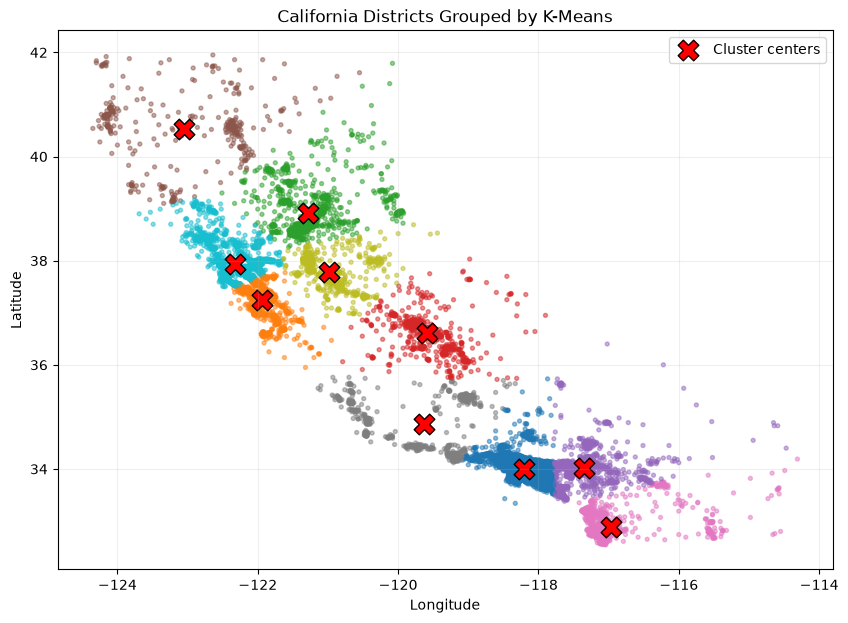

In [ ]:
plt.figure(figsize=(10,7))

plt.scatter(
    Longitude,
    Latitude,
    c=labels,
    cmap='tab10',
    s=8,
    alpha=0.5
)

plt.scatter(
    centers[:, 1],
    centers[:, 0],
    marker='X',
    s=220,
    c='red',
    edgecolors='black',
    label='Cluster centers'
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("California Districts Grouped by K-Means")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

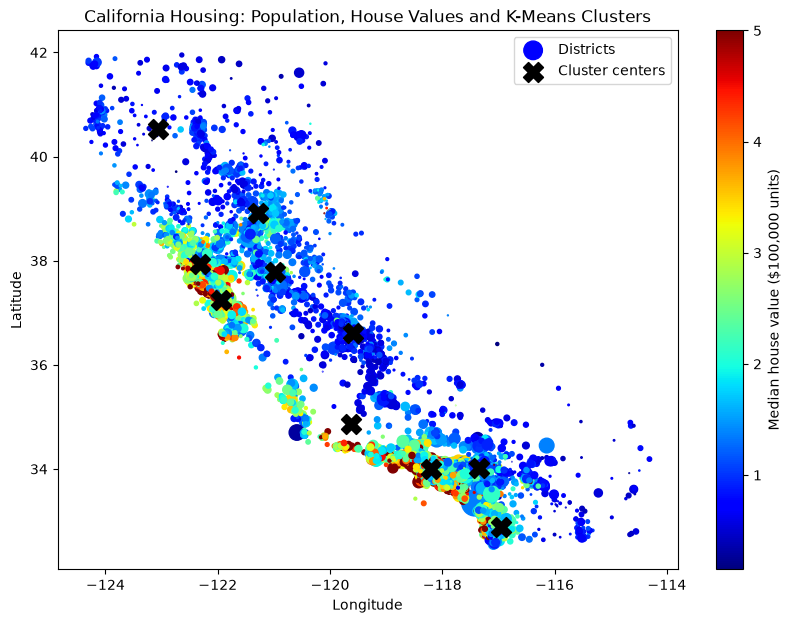

In [ ]:
housing_plot = housing_clean.copy()

# Add target values for visualization
housing_plot["MedHouseVal"] = housing_labels

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    housing_plot["Longitude"],
    housing_plot["Latitude"],
    s=housing_plot["Population"] / 100,
    c=housing_plot["MedHouseVal"],
    cmap="jet",
    # alpha=0.2,
    label="Districts"
)

# Overlay the K-Means cluster centers
plt.scatter(
    kmeans.cluster_centers_[:, 1],  # Longitude
    kmeans.cluster_centers_[:, 0],  # Latitude
    marker="X",
    s=200,
    c="black",
    # edgecolors="white",
    linewidths=1.2,
    label="Cluster centers"
)

plt.colorbar(scatter, label="Median house value ($100,000 units)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("California Housing: Population, House Values and K-Means Clusters")
plt.legend()
plt.show()


# ClusterSimilarity — Geographic Feature Transformer

## 1. Purpose

`ClusterSimilarity` is a custom scikit-learn transformer that converts geographic coordinates into similarity features based on K-Means cluster centers.

Instead of using only raw latitude and longitude, it provides the model with information about how close each housing district is to several geographic clusters.

## 2. How It Works

### `__init__()`
Accepts three parameters:

- `n_clusters` — number of geographic clusters.
- `gamma` — controls how quickly similarity decreases with distance.
- `random_state` — controls the reproducibility of K-Means initialization.

### `fit(X, y=None)`
Fits a K-Means model to the geographic coordinates and learns the cluster centers.

### `transform(X)`
Uses `rbf_kernel()` to calculate a similarity score between every input location and every cluster center.

### `get_feature_names_out()`
Returns readable names for the generated features, such as `Cluster 0 similarity` and `Cluster 1 similarity`.

## 3. RBF Kernel Similarity

The RBF kernel is defined as:

\[
K(x,c)=\exp\left(-\gamma\|x-c\|^2\right)
\]

Where:

- \(x\) represents a housing district's coordinates.
- \(c\) represents a cluster center.
- \(\gamma\) controls how quickly similarity decreases with distance.
- \(\|x-c\|^2\) is the squared Euclidean distance between the location and cluster center.

A similarity score close to **1** indicates a location close to the cluster center. A score close to **0** indicates a location farther away.

## 4. Example

With `n_clusters=10`, each housing district receives 10 similarity features.

For an input containing 16,512 rows and two geographic columns, the transformed output has shape:

`(16512, 10)`

Each output column represents similarity to one cluster center.

## 5. Why Inherit from Scikit-learn Classes?

The class inherits from:

- `BaseEstimator` — supports standard estimator functionality and parameter handling.
- `TransformerMixin` — provides `fit_transform()`.

This allows the transformer to be used inside a scikit-learn `Pipeline` and evaluated with cross-validation.

## 6. Advantages

- Converts raw geographic coordinates into informative similarity features.
- Helps the model represent regional patterns in housing values.
- Can be combined with other feature engineering steps.
- Fits cluster centers within the training data when used correctly inside cross-validation.

## 7. Important Considerations

- The number of clusters affects the representation.
- The `gamma` value affects the similarity scores and should be evaluated.
- Geographic coordinates are measured in degrees, so distance scaling can influence the results.
- Fit the transformer inside the full pipeline to avoid data leakage during cross-validation.

## 8. Role in the California Housing Project

We apply `ClusterSimilarity` to `Latitude` and `Longitude`, then pass the resulting similarity features and the remaining housing features to a `RandomForestRegressor`.

We evaluate whether these geographic features improve prediction performance by comparing cross-validation RMSE.


In [27]:
from sklearn.metrics.pairwise import rbf_kernel

In [28]:
class ClusterSimilarity(BaseEstimator, TransformerMixin):

    def __init__(self, n_clusters=10, gamma=1.0, random_state=42):
        self.n_clusters = n_clusters
        self.random_state = random_state
        self.gamma = gamma

    def fit(self, X, y=None):
        self.kmeans_ = KMeans(
            n_clusters=self.n_clusters,
            random_state=self.random_state,
            n_init=10
        )
        self.kmeans_.fit(X)
        self.kmeans_cluster_centers_ = self.kmeans_.cluster_centers_
        return self

    def transform(self, X):
        return rbf_kernel(
            X,
            self.kmeans_cluster_centers_,
            gamma=self.gamma
        )

    def get_feature_names_out(self, input_features=None):
        return [
            f'Cluster {i} similarity'
            for i in range(self.n_clusters)
        ]

In [29]:
cluster_adder = ClusterSimilarity(n_clusters=10, gamma=1.0)

cluster_similarities = cluster_adder.fit_transform(geo_features)

print(cluster_similarities.shape)
print(cluster_adder.get_feature_names_out())

(16512, 10)
['Cluster 0 similarity', 'Cluster 1 similarity', 'Cluster 2 similarity', 'Cluster 3 similarity', 'Cluster 4 similarity', 'Cluster 5 similarity', 'Cluster 6 similarity', 'Cluster 7 similarity', 'Cluster 8 similarity', 'Cluster 9 similarity']


In [19]:
from sklearn.compose import ColumnTransformer

In [47]:
geo_pipeline = Pipeline([
    ("cluster_similarity", ClusterSimilarity(n_clusters=10, gamma=1.0))
])

geo_preprocessing = ColumnTransformer([
    ("geo", geo_pipeline, ["Latitude", "Longitude"])
], remainder="passthrough")

model_pipeline = Pipeline([
    ("geographic_features", geo_preprocessing),
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("regression", RandomForestRegressor(random_state=42))
])

In [34]:
print(type(housing_clean))
print(housing_clean.columns)

<class 'pandas.DataFrame'>
Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude'],
      dtype='str')


In [ ]:
geo_scores = evaluate_model(
    model_pipeline,
    housing_clean,
    housing_labels,
    cv=5
)

List of RMSEs: [0.4865573  0.47284004 0.47221903 0.49997145 0.48382502]

RMSE summary
count    5.000000
mean     0.483083
std      0.011410
min      0.472219
25%      0.472840
50%      0.483825
75%      0.486557
max      0.499971
dtype: float64


In [56]:
feature_adder = CombinedAttributesAdder(
    features_to_add=[ 'latlong_ratio', 'room_per_person']
)

model_pipeline = Pipeline([
    ('feature_adder', feature_adder),
    ('preprocessing', geo_preprocessing),
    ('imputer', SimpleImputer(strategy="median")),
    ("regression", RandomForestRegressor(random_state=42))
])

In [ ]:
rmses = evaluate_model(
    model_pipeline,
    housing_clean,
    housing_labels,
    cv=5
)

List of RMSEs: [0.4795504  0.46799073 0.47128482 0.48986011 0.47997472]

RMSE summary
count    5.000000
mean     0.477732
std      0.008542
min      0.467991
25%      0.471285
50%      0.479550
75%      0.479975
max      0.489860
dtype: float64


In [57]:
rmses = evaluate_model(
    model_pipeline,
    housing_clean,
    housing_labels,
    cv=3
)

List of RMSEs: [0.46763064 0.48010478 0.48908154]

RMSE summary
count    3.000000
mean     0.478939
std      0.010773
min      0.467631
25%      0.473868
50%      0.480105
75%      0.484593
max      0.489082
dtype: float64


In [ ]:
#baseline + ['latlong_ratior', 'rooms_per_person'] + geo_features =  0.476381
#baseline + rooms_per_person + geo_features = 0.481450
#baseline + latlong_ratio + geo_features = 0.477732

In [ ]:
from sklearn.svm import SVR

In [ ]:
svr_pipeline = Pipeline([
    ("feature_adder", CombinedAttributesAdder(
        features_to_add=["latlong_ratio", "room_per_person"]
    )),
    ("geographic_features", geo_preprocessing),
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("regression", SVR(kernel="rbf"))
])

In [ ]:
from sklearn.base import clone


kernels = ["linear", "poly", "rbf"]

for kernel in kernels:
    model = clone(svr_pipeline)
    model.set_params(regression__kernel=kernel)

    scores = evaluate_model(
        model,
        housing_clean,
        housing_labels,
        cv=5
    )

    print(f"{kernel} mean RMSE: {scores.mean():.6f}")

List of RMSEs: [0.68246657 0.72600867 0.70474666 0.69162365 0.67436946]

RMSE summary
count    5.000000
mean     0.695843
std      0.020292
min      0.674369
25%      0.682467
50%      0.691624
75%      0.704747
max      0.726009
dtype: float64
linear mean RMSE: 0.695843
List of RMSEs: [0.8707803  3.25602474 3.51571732 1.07239881 0.60724429]

RMSE summary
count    5.000000
mean     1.864433
std      1.401647
min      0.607244
25%      0.870780
50%      1.072399
75%      3.256025
max      3.515717
dtype: float64
poly mean RMSE: 1.864433
List of RMSEs: [0.54306489 0.512141   0.51970439 0.54792263 0.54028483]

RMSE summary
count    5.000000
mean     0.532624
std      0.015718
min      0.512141
25%      0.519704
50%      0.540285
75%      0.543065
max      0.547923
dtype: float64
rbf mean RMSE: 0.532624


In [ ]:
from sklearn.neural_network import MLPRegressor

In [ ]:

mlp_pipeline = Pipeline([
    ("feature_adder", CombinedAttributesAdder(
        features_to_add=["latlong_ratio", "room_per_person"]
    )),
    ("geographic_features", geo_preprocessing),
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("regression", MLPRegressor(
        hidden_layer_sizes=(100,),
        max_iter=500,
        random_state=42,
        early_stopping=True
    ))
])

In [ ]:
mlp_scores = evaluate_model(
    mlp_pipeline,
    housing_clean,
    housing_labels,
    cv=5
)

List of RMSEs: [0.52241983 0.49779196 0.50621516 0.55915214 0.53711705]

RMSE summary
count    5.000000
mean     0.524539
std      0.024556
min      0.497792
25%      0.506215
50%      0.522420
75%      0.537117
max      0.559152
dtype: float64


In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

In [ ]:
gbr_pipeline = Pipeline([
    ("feature_adder", CombinedAttributesAdder(
        features_to_add=["latlong_ratio", "room_per_person"]
    )),
    ("geographic_features", geo_preprocessing),
    ("imputer", SimpleImputer(strategy="median")),
    ("regression", GradientBoostingRegressor(random_state=42))
])

In [ ]:
gbr_scores = evaluate_model(
    gbr_pipeline,
    housing_clean,
    housing_labels,
    cv=5
)

List of RMSEs: [0.51591521 0.5004051  0.51010075 0.52476335 0.52673151]

RMSE summary
count    5.000000
mean     0.515583
std      0.010829
min      0.500405
25%      0.510101
50%      0.515915
75%      0.524763
max      0.526732
dtype: float64


## Model Comparison After Random Forest

| Model | Mean CV RMSE |
|---|---:|
| MLP Regressor (Neural Network) | 0.515583 |
| Gradient Boosting Regressor | 0.524539 |
| SVR (RBF Kernel) | 0.532624 |
| SVR (Linear Kernel) | 0.695843 |
| SVR (Polynomial Kernel) | 1.864433 |

## Model Comparison — Observations

- **Random Forest** achieved the lowest reported mean CV RMSE of **0.476381** using engineered features and geographic cluster similarities.
- **MLP Regressor** achieved a mean CV RMSE of 0.515583, followed by Gradient Boosting at 0.524539.
- **SVR with an RBF kernel** scored 0.532624, while the linear and polynomial kernels performed worse.
- The polynomial SVR had the highest error (1.864433) and showed considerable variation across CV folds.
- Random Forest remains our winner because it produced the lowest reported prediction error among the tested models.

### Why Random Forest?

Random Forest combines predictions from multiple decision trees, helping capture nonlinear relationships and interactions between features. It also works well with engineered features and does not require feature scaling.

**Next step:** Tune Random Forest hyperparameters to see whether we can improve its performance further.

*Note: These results are preliminary comparisons. Using identical cross-validation splits for every model will make the ranking more reliable.*

In [39]:
from sklearn.model_selection import GridSearchCV, KFold

In [48]:
feature_adder = CombinedAttributesAdder(
    features_to_add=[ 'latlong_ratio', 'room_per_person']
)

model_pipeline = Pipeline([
    ('feature_adder', feature_adder),
    ('preprocessing', geo_preprocessing),
    ('imputer', SimpleImputer(strategy="median")),
    ("regression", RandomForestRegressor(random_state=42))
])

In [31]:
param_grid = {
    "regression__n_estimators": [100, 200, 300],
    "regression__max_features": [0.6, 0.8, 1.0],
    "regression__max_depth": [None, 20, 30],
    "regression__min_samples_leaf": [1, 2, 4],
}

In [52]:
from sklearn.model_selection import RandomizedSearchCV

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

random_search = RandomizedSearchCV(
    estimator=model_pipeline,
    param_distributions=param_grid,
    n_iter=20,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    random_state=42,
    verbose=2
)

random_search.fit(housing_clean, housing_labels)

In [63]:
print("Best parameters:", random_search.best_params_)
print("Best CV RMSE:", -random_search.best_score_)

Best parameters: {'regression__n_estimators': 200, 'regression__min_samples_leaf': 1, 'regression__max_features': 0.6, 'regression__max_depth': 30}
Best CV RMSE: 0.4604531205667239


In [64]:
model_pipeline.get_params().keys()

dict_keys(['memory', 'steps', 'transform_input', 'verbose', 'feature_adder', 'preprocessing', 'imputer', 'regression', 'feature_adder__features_to_add', 'preprocessing__n_jobs', 'preprocessing__remainder', 'preprocessing__sparse_threshold', 'preprocessing__transformer_weights', 'preprocessing__transformers', 'preprocessing__verbose', 'preprocessing__verbose_feature_names_out', 'preprocessing__geo', 'preprocessing__geo__memory', 'preprocessing__geo__steps', 'preprocessing__geo__transform_input', 'preprocessing__geo__verbose', 'preprocessing__geo__cluster_similarity', 'preprocessing__geo__cluster_similarity__gamma', 'preprocessing__geo__cluster_similarity__n_clusters', 'preprocessing__geo__cluster_similarity__random_state', 'imputer__add_indicator', 'imputer__copy', 'imputer__fill_value', 'imputer__keep_empty_features', 'imputer__missing_values', 'imputer__strategy', 'regression__bootstrap', 'regression__ccp_alpha', 'regression__criterion', 'regression__max_depth', 'regression__max_featu

In [43]:
model_pipeline.set_params(
    regression__n_estimators=200,
    regression__max_features=0.6,
    regression__max_depth=30,
    regression__min_samples_leaf=1
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_adder', ...), ('preprocessing', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,features_to_add,"['latlong_ratio', 'room_per_person']"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('geo', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough

In [36]:
param_grid_geo = {
    "preprocessing__geo__cluster_similarity__n_clusters": [
        5, 8, 10, 15, 20
    ],
    "preprocessing__geo__cluster_similarity__gamma": [
        0.1, 0.5, 1.0, 2.0
    ]
}

In [40]:
cv = KFold(n_splits=3, shuffle=True, random_state=42)

In [44]:
from sklearn.model_selection import GridSearchCV

geo_search = GridSearchCV(
    estimator=model_pipeline,
    param_grid=param_grid_geo,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    verbose=2
)

geo_search.fit(housing_clean, housing_labels)

Fitting 3 folds for each of 20 candidates, totalling 60 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'preprocessing__geo__cluster_similarity__gamma': [0.1, 0.5, ...], 'preprocessing__geo__cl..._similarity__n_clusters': [5, 8, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more 

In [46]:
geo_search.best_params_

{'preprocessing__geo__cluster_similarity__gamma': 0.5,
 'preprocessing__geo__cluster_similarity__n_clusters': 20}

In [47]:
geo_search.best_score_

np.float64(-0.45071991624476543)

In [49]:
model_pipeline.set_params(
    preprocessing__geo__cluster_similarity__n_clusters=20,
    preprocessing__geo__cluster_similarity__gamma=0.5,
    regression__n_estimators=200,
    regression__max_features=0.6,
    regression__max_depth=30,
    regression__min_samples_leaf=1
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_adder', ...), ('preprocessing', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,features_to_add,"['latlong_ratio', 'room_per_person']"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('geo', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough

In [49]:
model_pipeline.set_params(
    feature_adder__features_to_add=[
        "latlong_ratio",
        "room_per_person"
    ],
    preprocessing__geo__cluster_similarity__n_clusters=20,
    preprocessing__geo__cluster_similarity__gamma=0.5
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_adder', ...), ('preprocessing', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,features_to_add,"['latlong_ratio', 'room_per_person']"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('geo', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough

In [50]:
param_distributions_rf = {
    "regression__n_estimators": [100, 200, 300, 500],
    "regression__max_features": [0.4, 0.6, 0.8, 1.0],
    "regression__max_depth": [None, 20, 30, 40],
    "regression__min_samples_leaf": [1, 2, 4, 6]
}

In [53]:
random_search_rf = RandomizedSearchCV(
    estimator=model_pipeline,
    param_distributions=param_distributions_rf,
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    random_state=42,
    verbose=2
)

random_search_rf.fit(housing_clean, housing_labels)

Fitting 3 folds for each of 30 candidates, totalling 90 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'regression__max_depth': [None, 20, ...], 'regression__max_features': [0.4, 0.6, ...], 'regression__min_samples_leaf': [1, 2, ...], 'regression__n_estimators': [100, 200, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations ot

In [54]:
random_search_rf.best_params_

{'regression__n_estimators': 500,
 'regression__min_samples_leaf': 2,
 'regression__max_features': 0.4,
 'regression__max_depth': 40}

In [58]:
random_search_rf.best_score_

np.float64(-0.4425362717048304)

In [59]:
model_pipeline.set_params(
    feature_adder__features_to_add=[
        "latlong_ratio",
        "room_per_person"
    ],
    preprocessing__geo__cluster_similarity__n_clusters=20,
    preprocessing__geo__cluster_similarity__gamma=0.5,
    regression__n_estimators=500,
    regression__max_features=0.4,
    regression__max_depth=40,
    regression__min_samples_leaf=2
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_adder', ...), ('preprocessing', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,features_to_add,"['latlong_ratio', 'room_per_person']"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('geo', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough

In [60]:
final_cv_scores = evaluate_model(
    model_pipeline,
    housing_clean,
    housing_labels,
    cv=cv
)

List of RMSEs: [0.44438008 0.43872879 0.44449994]

RMSE summary
count    3.000000
mean     0.442536
std      0.003298
min      0.438729
25%      0.441554
50%      0.444380
75%      0.444440
max      0.444500
dtype: float64


In [61]:
param_distributions_joint = {
    "preprocessing__geo__cluster_similarity__n_clusters": [10, 15, 20, 25],
    "preprocessing__geo__cluster_similarity__gamma": [0.1, 0.3, 0.5, 1.0],

    "regression__n_estimators": [200, 300, 500],
    "regression__max_features": [0.3, 0.4, 0.6, 0.8],
    "regression__max_depth": [20, 30, 40, None],
    "regression__min_samples_leaf": [1, 2, 4, 6]
}

In [62]:
joint_search = RandomizedSearchCV(
    estimator=model_pipeline,
    param_distributions=param_distributions_joint,
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    random_state=42,
    verbose=2
)

joint_search.fit(housing_clean, housing_labels)

Fitting 3 folds for each of 30 candidates, totalling 90 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'preprocessing__geo__cluster_similarity__gamma': [0.1, 0.3, ...], 'preprocessing__geo__cl..._similarity__n_clusters': [10, 15, ...], 'regression__max_depth': [20, 30, ...], 'regression__max_features': [0.3, 0.4, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimato

In [63]:
joint_search.best_score_

np.float64(-0.44287871978894217)

In [64]:
joint_search.best_params_

{'regression__n_estimators': 200,
 'regression__min_samples_leaf': 2,
 'regression__max_features': 0.4,
 'regression__max_depth': 30,
 'preprocessing__geo__cluster_similarity__n_clusters': 20,
 'preprocessing__geo__cluster_similarity__gamma': 0.3}

In [50]:
final_pipeline = model_pipeline.set_params(
    feature_adder__features_to_add=[
        "latlong_ratio",
        "room_per_person"
    ],
    preprocessing__geo__cluster_similarity__n_clusters=20,
    preprocessing__geo__cluster_similarity__gamma=0.5,
    regression__n_estimators=500,
    regression__max_features=0.4,
    regression__max_depth=40,
    regression__min_samples_leaf=2
)

In [51]:
final_pipeline.fit(housing_clean, housing_labels)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_adder', ...), ('preprocessing', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,features_to_add,"['latlong_ratio', 'room_per_person']"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('geo', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough

In [18]:
X_test = strat_test_set.drop('MedHouseVal',axis=1)
y_test = strat_test_set['MedHouseVal'].copy()

In [68]:
final_predictions = final_pipeline.predict(X_test)

In [70]:
final_rmse = root_mean_squared_error(y_test, final_predictions)
print("Root Mean Squared Error on test set:",final_rmse)

Root Mean Squared Error on test set: 0.41360670041352054


In [54]:
import joblib
from pathlib import Path

In [55]:
import joblib
from pathlib import Path

model_dir = Path("models")
model_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / "california_housing_pipeline.joblib"

# joblib.dump(final_pipeline, model_path)

# print(f'Pipeline saved at: {model_path}')

In [56]:
print(model_path.exists())
print(f'File size: {model_path.stat().st_size / (1024**2):.2f} MB')

False


FileNotFoundError: [WinError 2] The system cannot find the file specified: 'models\\california_housing_pipeline.joblib'

In [57]:
loaded_pipeline = joblib.load(model_path)

print("Pipeline loaded successfully!")

FileNotFoundError: [Errno 2] No such file or directory: 'models\\california_housing_pipeline.joblib'

In [75]:
original_predictions = final_pipeline.predict(X_test)
loaded_predictions = loaded_pipeline.predict(X_test)

print(
    "Predictions match:",
    np.allclose(original_predictions, loaded_predictions)
)

Predictions match: True


In [1]:
import sys
from pathlib import Path

project_root = Path.cwd()

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.transformers import (
    CombinedAttributesAdder,
    ClusterSimilarity
)

ModuleNotFoundError: No module named 'src'

In [2]:
path = (r'D:\california-housing-2\src\transformers.py')

In [59]:
import sys
from pathlib import Path

transformers_path = Path(
    r"D:\california-housing-2\src\transformers.py"
)

project_root = transformers_path.parent.parent

sys.path.insert(0, str(project_root))

from src.transformers import (
    CombinedAttributesAdder,
    ClusterSimilarity
)

print("Import successful, bro!")

Import successful, bro!


In [60]:
from src.transformers import (
    CombinedAttributesAdder,
    ClusterSimilarity,
)

print(CombinedAttributesAdder.__module__)
print(ClusterSimilarity.__module__)

src.transformers
src.transformers


In [61]:
model_path = Path(
    r"D:\california-housing-2\models\california_housing_pipeline.joblib"
)

loaded_pipeline = joblib.load(model_path)

print('Model loaded successfully!')

Model loaded successfully!


In [62]:
print(
    "Feature adder:",
    type(loaded_pipeline.named_steps["feature_adder"]).__module__
)

print(
    "Cluster similarity:",
    type(
        loaded_pipeline.named_steps["preprocessing"]
        .named_transformers_["geo"]
        .named_steps["cluster_similarity"]
    ).__module__
)

Feature adder: src.transformers
Cluster similarity: src.transformers


In [52]:
import numpy as np

original_predictions = final_pipeline.predict(X_test)
loaded_predictions = loaded_pipeline.predict(X_test)

print(
    "Predictions match:",
    np.allclose(original_predictions, loaded_predictions)
)

Predictions match: True


In [53]:
import joblib
from pathlib import Path

model_path = Path(
    r"D:\california-housing-2\models\california_housing_pipeline.joblib"
)

backup_path = model_path.with_name(
    "california_housing_pipeline_backup.joblib"
)

if not backup_path.exists():
    import shutil
    shutil.copy2(model_path, backup_path)

joblib.dump(loaded_pipeline, model_path)

print("Pipeline re-saved.")

Pipeline re-saved.


In [54]:
X_test.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
5241,8.2816,29.0,6.715625,1.054167,2184.0,2.275000,34.12,-118.39
17352,5.0099,24.0,7.137809,1.084806,855.0,3.021201,34.89,-120.42
3505,4.3839,36.0,5.283636,0.981818,808.0,2.938182,34.25,-118.45
7777,3.2708,35.0,5.491694,1.079734,1072.0,3.561462,33.91,-118.10
14155,4.3529,38.0,6.154723,1.000000,1495.0,2.434853,32.77,-117.07


In [55]:
y_test.head()

5241     5.00001
17352    1.62500
3505     2.04600
7777     1.59700
14155    1.84000
Name: MedHouseVal, dtype: float64

In [35]:
geo_pipeline = Pipeline([
    ("cluster_similarity", ClusterSimilarity(n_clusters=10, gamma=1.0))
])

geo_preprocessing = ColumnTransformer([
    ("geo", geo_pipeline, ["Latitude", "Longitude"])
], remainder="passthrough")

# model_pipeline = Pipeline([
#     ("geographic_features", geo_preprocessing),
#     ("imputer", SimpleImputer(strategy="median")),
#     ("scaler", StandardScaler()),
#     ("regression", RandomForestRegressor(random_state=42))
# ])

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

feature_adder = CombinedAttributesAdder(
    features_to_add=["latlong_ratio", "latlong_ratio", "bed_room"]
)

xgb_pipeline = Pipeline([
    ("feature_adder", feature_adder),
    ("geographic_features", geo_preprocessing),
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("regression", XGBRegressor(
        objective="reg:squarederror",
        eval_metric="rmse",
        random_state=42,
        n_jobs=1
    ))
])

In [65]:
from sklearn.model_selection import cross_val_score

In [37]:
from scipy.stats import randint, uniform, loguniform

param_distributions = {
    # Geographic hyperparameters
    "geographic_features__geo__cluster_similarity__n_clusters": [
        5, 10, 15, 20, 25, 30
    ],
    "geographic_features__geo__cluster_similarity__gamma": [
        0.1, 0.25, 0.5, 1.0, 2.0
    ],

    # XGBoost hyperparameters
    "regression__n_estimators": randint(300, 1001),
    "regression__learning_rate": loguniform(0.02, 0.15),
    "regression__max_depth": randint(3, 9),
    "regression__min_child_weight": randint(1, 7),
    "regression__subsample": uniform(0.7, 0.3),
    "regression__colsample_bytree": uniform(0.7, 0.3),
    "regression__reg_alpha": [0, 0.01, 0.1, 1.0],
    "regression__reg_lambda": [1, 2, 5, 10]
}

In [38]:
from sklearn.model_selection import RandomizedSearchCV, KFold

cv_strategy = KFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_distributions,
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=cv_strategy,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    refit=True
)

xgb_search.fit(housing, housing_labels)

print("Best CV RMSE:", -xgb_search.best_score_)
print("Best parameters:", xgb_search.best_params_)

Fitting 3 folds for each of 30 candidates, totalling 90 fits
Best CV RMSE: 0.43133176942733265
Best parameters: {'geographic_features__geo__cluster_similarity__gamma': 1.0, 'geographic_features__geo__cluster_similarity__n_clusters': 20, 'regression__colsample_bytree': np.float64(0.8099085529881075), 'regression__learning_rate': np.float64(0.050132478040090245), 'regression__max_depth': 8, 'regression__min_child_weight': 3, 'regression__n_estimators': 866, 'regression__reg_alpha': 1.0, 'regression__reg_lambda': 10, 'regression__subsample': np.float64(0.8400288679743939)}


In [39]:
cv10 = KFold(n_splits=10, shuffle=True, random_state=42)

tuned_xgb_scores = -cross_val_score(
    xgb_search.best_estimator_,
    housing,
    housing_labels,
    scoring="neg_root_mean_squared_error",
    cv=cv10,
    n_jobs=1
)

print("10-fold RMSE scores:", tuned_xgb_scores)
print("Mean RMSE:", tuned_xgb_scores.mean())
print("Std RMSE:", tuned_xgb_scores.std())

10-fold RMSE scores: [0.39025666 0.43617401 0.44163833 0.41603411 0.40431237 0.43851765
 0.4269945  0.44236935 0.39538399 0.42141317]
Mean RMSE: 0.4213094145316353
Std RMSE: 0.0183284661224165


In [40]:
import pandas as pd
import matplotlib.pyplot as plt

best_xgb = xgb_search.best_estimator_

# Get the trained XGBoost model
xgb_model = best_xgb.named_steps["regression"]

# Get feature names after geographic preprocessing
feature_names = (
    best_xgb.named_steps["geographic_features"]
    .get_feature_names_out()
)

# Extract feature importances
importances = xgb_model.feature_importances_

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

print(importance_df)

                       feature  importance
20           remainder__MedInc    0.188082
26    remainder__latlong_ratio    0.065816
15  geo__Cluster 15 similarity    0.061357
7    geo__Cluster 7 similarity    0.060401
12  geo__Cluster 12 similarity    0.058659
2    geo__Cluster 2 similarity    0.048671
14  geo__Cluster 14 similarity    0.043156
1    geo__Cluster 1 similarity    0.042285
25         remainder__AveOccup    0.041719
27  remainder__room_per_person    0.040867
10  geo__Cluster 10 similarity    0.032967
16  geo__Cluster 16 similarity    0.028199
4    geo__Cluster 4 similarity    0.027966
9    geo__Cluster 9 similarity    0.027314
13  geo__Cluster 13 similarity    0.026042
0    geo__Cluster 0 similarity    0.024676
6    geo__Cluster 6 similarity    0.021794
5    geo__Cluster 5 similarity    0.020028
3    geo__Cluster 3 similarity    0.019769
21         remainder__HouseAge    0.018813
22         remainder__AveRooms    0.018436
17  geo__Cluster 17 similarity    0.017051
18  geo__Cl

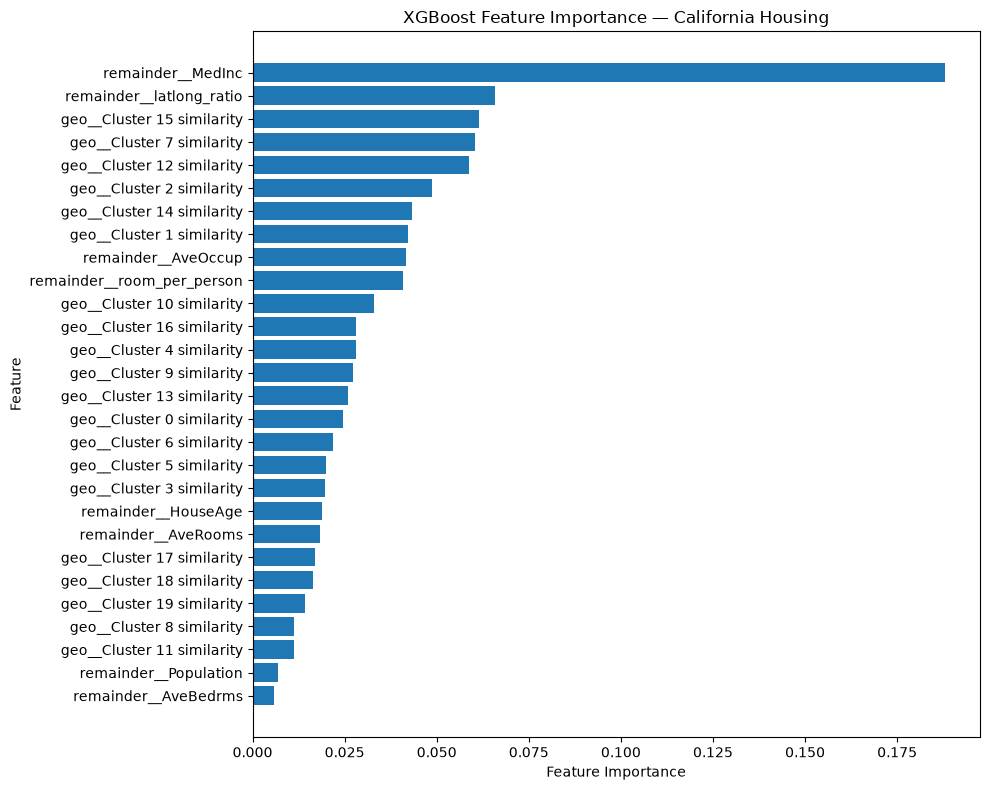

In [41]:
importance_df = importance_df.sort_values("importance")

plt.figure(figsize=(10, 8))

plt.barh(
    importance_df["feature"],
    importance_df["importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("XGBoost Feature Importance — California Housing")
plt.tight_layout()
plt.show()

In [48]:
feature_adder = CombinedAttributesAdder(
    features_to_add=["latlong_ratio", "room_per_person", "bed_room"]
)

xgb_pipeline_no_rooms_per_person = Pipeline([
    ("feature_adder", feature_adder),
    ("geographic_features", geo_preprocessing),
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("regression", XGBRegressor(
        objective="reg:squarederror",
        eval_metric="rmse",
        random_state=42,
        n_jobs=1,
        **{
            key.removeprefix("regression__"): value
            for key, value in xgb_search.best_params_.items()
            if key.startswith("regression__")
        }
    ))
])

In [49]:
from sklearn.model_selection import KFold, cross_val_score
import numpy as np

cv10 = KFold(n_splits=10, shuffle=True, random_state=42)

scores_no_rooms_per_person = -cross_val_score(
    xgb_pipeline_no_rooms_per_person,
    housing,
    housing_labels,
    scoring="neg_root_mean_squared_error",
    cv=cv10,
    n_jobs=1
)

print("Fold RMSEs:", scores_no_rooms_per_person)
print("Mean RMSE:", scores_no_rooms_per_person.mean())
print("Std RMSE:", scores_no_rooms_per_person.std())

Fold RMSEs: [0.39608713 0.44103958 0.45491644 0.42680149 0.41382506 0.44409664
 0.43165632 0.4493313  0.40432628 0.42779175]
Mean RMSE: 0.42898719946688824
Std RMSE: 0.018421617207358545


In [ ]:
#xgb + 'latlong_ratio' = Fold RMSEs: [0.39710575 0.44323191 0.44183795 0.42694886 0.40818432 0.43995886
#  0.42873117 0.44477409 0.40126609 0.4292028 ]
# Mean RMSE: 0.4261241803620647
# Std RMSE: 0.016963494886244265

#xgb + 'room_per_person'+ 'latlong_ratio' + 'incpop_ratio' = Fold RMSEs: [0.39841241 0.44281375 0.4478763  0.42839065 0.41347126 0.44377327
#  0.43050336 0.45911451 0.40130521 0.43098915]
# Mean RMSE: 0.4296649885380425
# Std RMSE: 0.0190215066865314

#xgb + 'room_per_person'+ 'latlong_ratio' + 'bed_room' = Fold RMSEs: [0.39608713 0.44103958 0.45491644 0.42680149 0.41382506 0.44409664
#  0.43165632 0.4493313  0.40432628 0.42779175]
# Mean RMSE: 0.42898719946688824
# Std RMSE: 0.018421617207358545

In [50]:
final_xgb_model = xgb_search.best_estimator_

In [52]:
xgb_test_predictions = final_xgb_model.predict(X_test)

xgb_test_rmse = root_mean_squared_error(
    y_test,
    xgb_test_predictions
)

print(f"XGBoost Test RMSE: {xgb_test_rmse:.5f}")
print(f"Approximate dollar RMSE: ${xgb_test_rmse * 100_000:,.2f}")

XGBoost Test RMSE: 0.40057
Approximate dollar RMSE: $40,057.08


In [53]:
from sklearn.metrics import r2_score

xgb_test_r2 = r2_score(y_test, xgb_test_predictions)

print(f"XGBoost Test R² Score: {xgb_test_r2:.4f}")
print(f"XGBoost Test R² Score: {xgb_test_r2 * 100:.2f}%")

XGBoost Test R² Score: 0.8769
XGBoost Test R² Score: 87.69%


In [63]:
rf_test_predictions = loaded_pipeline.predict(X_test)

In [64]:
from sklearn.metrics import r2_score

rf_test_r2 = r2_score(y_test, rf_test_predictions)

print(f"Random Forest Test R²: {rf_test_r2:.4f}")

Random Forest Test R²: 0.8687


In [66]:
from src.transformers import CombinedAttributesAdder, ClusterSimilarity

print(CombinedAttributesAdder.__module__)
print(ClusterSimilarity.__module__)

src.transformers
src.transformers


In [69]:
from src.transformers import CombinedAttributesAdder, ClusterSimilarity

geo_pipeline = Pipeline([
    ("cluster_similarity", ClusterSimilarity(
        n_clusters=20,
        gamma=1.0
    ))
])

geo_preprocessing = ColumnTransformer([
    ("geo", geo_pipeline, ["Latitude", "Longitude"])
], remainder="passthrough")

In [70]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

feature_adder = CombinedAttributesAdder(
    features_to_add=["latlong_ratio", "room_per_person"]
)

xgb_params = {
    key.removeprefix("regression__"): value
    for key, value in xgb_search.best_params_.items()
    if key.startswith("regression__")
}

final_xgb_model = Pipeline([
    ("feature_adder", feature_adder),
    ("geographic_features", geo_preprocessing),
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("regression", XGBRegressor(
        objective="reg:squarederror",
        eval_metric="rmse",
        random_state=42,
        n_jobs=1,
        **xgb_params
    ))
])

In [71]:
final_xgb_model.fit(housing, housing_labels)

new_predictions = final_xgb_model.predict(X_test)

print(
    "Predictions match:",
    np.allclose(new_predictions, xgb_test_predictions, atol=1e-6)
)

Predictions match: False


In [72]:
best_pipeline = xgb_search.best_estimator_

print(best_pipeline)
print("\nBest parameters:")
print(xgb_search.best_params_)

Pipeline(steps=[('feature_adder',
                 CombinedAttributesAdder(features_to_add=['latlong_ratio',
                                                          'room_per_person'])),
                ('geographic_features',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('geo',
                                                  Pipeline(steps=[('cluster_similarity',
                                                                   ClusterSimilarity(n_clusters=20))]),
                                                  ['Latitude', 'Longitude'])])),
                ('imputer', SimpleImputer(strategy='median')),
                ('sca...
                              gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None,
                              learning_rate=np.float64(0.050132478040090245),
                              max_bin=None

In [73]:
original_geo = (
    best_pipeline
    .named_steps["geographic_features"]
    .named_transformers_["geo"]
    .named_steps["cluster_similarity"]
)

print("Original cluster count:", original_geo.n_clusters)
print("Original gamma:", original_geo.gamma)

Original cluster count: 20
Original gamma: 1.0


In [74]:
import numpy as np

print("Original predictions (first 5):", xgb_test_predictions[:5])
print("Rebuilt predictions (first 5):", new_predictions[:5])

print(
    "Maximum absolute difference:",
    np.max(np.abs(xgb_test_predictions - new_predictions))
)

print(
    "Mean absolute difference:",
    np.mean(np.abs(xgb_test_predictions - new_predictions))
)

Original predictions (first 5): [4.958829  1.7951391 1.9409214 1.7296554 2.1710122]
Rebuilt predictions (first 5): [4.9128222 1.9118948 1.8765306 1.7310668 2.2144125]
Maximum absolute difference: 0.36337924
Mean absolute difference: 0.051406942


In [75]:
best_pipeline = xgb_search.best_estimator_

original_check = best_pipeline.predict(X_test)

print(
    "Original predictions preserved:",
    np.allclose(original_check, xgb_test_predictions)
)

Original predictions preserved: True


In [76]:
original_geo = (
    best_pipeline
    .named_steps["geographic_features"]
    .named_transformers_["geo"]
    .named_steps["cluster_similarity"]
)

print("Parameters:", original_geo.get_params())
print("Cluster centers:", original_geo.kmeans_.cluster_centers_[:3])

Parameters: {'gamma': 1.0, 'n_clusters': 20, 'random_state': 42}
Cluster centers: [[  37.85024859 -122.26496717]
 [  33.88214612 -116.56347032]
 [  36.67336077 -119.64635117]]


In [77]:
from src.transformers import CombinedAttributesAdder, ClusterSimilarity

print("Imported feature adder:", CombinedAttributesAdder.__module__)
print("Imported cluster transformer:", ClusterSimilarity.__module__)

print(
    "Original feature-adder class:",
    best_pipeline.named_steps["feature_adder"].__class__
)

print(
    "Original cluster class:",
    original_geo.__class__
)

Imported feature adder: src.transformers
Imported cluster transformer: src.transformers
Original feature-adder class: <class '__main__.CombinedAttributesAdder'>
Original cluster class: <class '__main__.ClusterSimilarity'>


In [78]:
from src.transformers import (
    CombinedAttributesAdder as ImportedFeatureAdder,
    ClusterSimilarity as ImportedClusterSimilarity,
)

best_pipeline = xgb_search.best_estimator_

# Preserve the fitted transformer objects and their learned state.
feature_adder = best_pipeline.named_steps["feature_adder"]
original_geo = (
    best_pipeline
    .named_steps["geographic_features"]
    .named_transformers_["geo"]
    .named_steps["cluster_similarity"]
)

feature_adder.__class__ = ImportedFeatureAdder
original_geo.__class__ = ImportedClusterSimilarity

print(type(feature_adder))
print(type(original_geo))

<class 'src.transformers.CombinedAttributesAdder'>
<class 'src.transformers.ClusterSimilarity'>


In [79]:
import numpy as np

predictions_after_fix = best_pipeline.predict(X_test)

print(
    "Predictions preserved:",
    np.allclose(
        predictions_after_fix,
        xgb_test_predictions,
        atol=1e-7
    )
)

Predictions preserved: True


In [80]:
import joblib
from pathlib import Path

model_path = Path(
    "models/xgboost_california_housing_pipeline.joblib"
)
model_path.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(best_pipeline, model_path)

print(f"Saved final XGBoost model to: {model_path}")

PicklingError: Can't pickle <class '__main__.ClusterSimilarity'>: it's not the same object as __main__.ClusterSimilarity

In [81]:
import joblib

print(best_pipeline.named_steps["feature_adder"].__class__.__module__)

geo_pipeline = (
    best_pipeline
    .named_steps["geographic_features"]
    .named_transformers_["geo"]
)

print(geo_pipeline.named_steps["cluster_similarity"].__class__.__module__)

src.transformers
src.transformers


In [82]:
import sys

print("Feature adder:")
print(type(best_pipeline.named_steps["feature_adder"]))
print(type(best_pipeline.named_steps["feature_adder"]).__module__)

geo_pipeline = (
    best_pipeline
    .named_steps["geographic_features"]
    .named_transformers_["geo"]
)

print("\nCluster similarity:")
print(type(geo_pipeline.named_steps["cluster_similarity"]))
print(type(geo_pipeline.named_steps["cluster_similarity"]).__module__)

print("\nOld notebook class still registered:")
print("CombinedAttributesAdder:", 
      getattr(sys.modules["__main__"], "CombinedAttributesAdder", None))

print("ClusterSimilarity:",
      getattr(sys.modules["__main__"], "ClusterSimilarity", None))

Feature adder:
<class 'src.transformers.CombinedAttributesAdder'>
src.transformers

Cluster similarity:
<class 'src.transformers.ClusterSimilarity'>
src.transformers

Old notebook class still registered:
CombinedAttributesAdder: <class 'src.transformers.CombinedAttributesAdder'>
ClusterSimilarity: <class 'src.transformers.ClusterSimilarity'>


In [83]:
import numpy as np

current_predictions = best_pipeline.predict(X_test)

print(
    "Predictions unchanged:",
    np.allclose(current_predictions, xgb_test_predictions)
)

Predictions unchanged: True


In [19]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent

if not (PROJECT_ROOT / "src" / "transformers.py").exists():
    raise FileNotFoundError(
        f"Could not find src/transformers.py from {PROJECT_ROOT}"
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.transformers import (
    CombinedAttributesAdder,
    ClusterSimilarity
)

In [20]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor



# 1. Add custom features
feature_adder = CombinedAttributesAdder(
    features_to_add=["latlong_ratio", "room_per_person"]
)

# 2. Geographic feature pipeline
geo_pipeline = Pipeline([
    (
        "cluster_similarity",
        ClusterSimilarity(
            n_clusters=20,
            gamma=1.0,
            random_state=42
        )
    )
])

geo_preprocessing = ColumnTransformer([
    ("geo", geo_pipeline, ["Latitude", "Longitude"])
], remainder="passthrough")

# 3. Complete XGBoost pipeline
final_xgb_pipeline = Pipeline([
    ("feature_adder", feature_adder),
    ("geographic_features", geo_preprocessing),
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("regression", XGBRegressor(
        n_estimators=866,
        learning_rate=0.050132478040090245,
        max_depth=8,
        min_child_weight=3,
        subsample=0.8400288679743939,
        colsample_bytree=0.8099085529881075,
        reg_alpha=1.0,
        reg_lambda=10,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    ))
])

In [21]:
final_xgb_pipeline.fit(housing, housing_labels)

print("XGBoost pipeline fitted successfully!")

XGBoost pipeline fitted successfully!


In [22]:
import numpy as np
from sklearn.metrics import mean_squared_error, r2_score

# Generate predictions
test_predictions = final_xgb_pipeline.predict(X_test)

# Calculate evaluation metrics
test_rmse = np.sqrt(
    mean_squared_error(y_test, test_predictions)
)

test_r2 = r2_score(y_test, test_predictions)

print(f"Test RMSE: {test_rmse:.5f}")
print(f"Test RMSE in dollars: ${test_rmse * 100_000:,.2f}")
print(f"Test R²: {test_r2:.4f}")
print(f"Test R² percentage: {test_r2 * 100:.2f}%")
print(
    "All predictions finite:",
    np.isfinite(test_predictions).all()
)

Test RMSE: 0.40182
Test RMSE in dollars: $40,181.81
Test R²: 0.8761
Test R² percentage: 87.61%
All predictions finite: True


In [23]:
import joblib
from pathlib import Path

# PROJECT_ROOT should point to your project root directory
MODEL_PATH = (
    PROJECT_ROOT
    / "models"
    / "xgboost_california_housing_pipeline.joblib"
)

MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(final_xgb_pipeline, MODEL_PATH)

print(f"Model saved successfully to:\n{MODEL_PATH}")

Model saved successfully to:
d:\california-housing-2\models\xgboost_california_housing_pipeline.joblib


In [24]:
test_predictions = final_xgb_pipeline.predict(X_test)

In [25]:
loaded_pipeline = joblib.load(MODEL_PATH)

loaded_predictions = loaded_pipeline.predict(X_test)

print(
    "Predictions preserved:",
    np.allclose(test_predictions, loaded_predictions)
)

print(
    "Maximum prediction difference:",
    np.max(np.abs(test_predictions - loaded_predictions))
)

Predictions preserved: True
Maximum prediction difference: 0.0


In [ ]:
Fitting 3 folds for each of 30 candidates, totalling 90 fits
Best CV RMSE: 0.43133176942733265
Best parameters: {'geographic_features__geo__cluster_similarity__gamma': 1.0, 'geographic_features__geo__cluster_similarity__n_clusters': 20, 'regression__colsample_bytree': np.float64(0.8099085529881075), 'regression__learning_rate': np.float64(0.050132478040090245), 'regression__max_depth': 8, 'regression__min_child_weight': 3, 'regression__n_estimators': 866, 'regression__reg_alpha': 1.0, 'regression__reg_lambda': 10, 'regression__subsample': np.float64(0.8400288679743939)}